# Units and Dimensions as Linear Algebra

**Buckingham Pi, scaling laws, and natural scales** — companion to
[`dgs/units_dimensions.py`](../dgs/units_dimensions.py).

The repo already has two unit tools: [`dgs/dimensional_analysis.py`](../dgs/dimensional_analysis.py)
*checks* that known EM equations balance, and [`dgs/chem_units.py`](../dgs/chem_units.py)
*converts* quantities. This notebook does the third thing: it **derives**
relations nobody handed you.

**The one idea.** A quantity's dimension is a vector of exponents over the SI
base dimensions $(M, L, T, I, \Theta, N, J)$. Multiplying quantities adds the
vectors. So asking "which products $x_1^{a_1}x_2^{a_2}\cdots$ have the
dimension I want?" is a linear system
$$D\,\mathbf a=\mathbf b ,$$
where column $j$ of $D$ is the dimension vector of $x_j$.

| Right-hand side | Meaning of the solutions | Section |
|---|---|---|
| $\mathbf b=\mathbf 0$ | dimensionless groups; there are $n-\operatorname{rank}D$ of them (Buckingham Pi) | 3, 4 |
| $\mathbf b\neq\mathbf 0$, unique | a scaling law, up to a pure number | 2, 5, 6 |

**What it cannot do**, stated up front: it never gives the dimensionless
prefactor, and it gives no unique answer when a dimensionless group exists
among the variables. Both limits are demonstrated below, not just mentioned.

In [1]:
import sys, pathlib, math
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.units_dimensions import (
    BASE, DIMS, CONSTANTS, DIMENSIONLESS, dim, dim_mul, dim_div, dim_pow, dim_str,
    check_homogeneous, dimension_matrix, count_pi_groups, buckingham_pi, group_dimension,
    solve_power_law, power_law_str, scale, evaluate_group,
    light_travel_time, light_distance, joule_to_ev, ev_to_joule,
    energy_to_wavelength, mass_to_rest_energy_ev, HBAR_C_MEV_FM, C_LIGHT,
)
print("base dimensions:", BASE)

base dimensions: ('M', 'L', 'T', 'I', 'Th', 'N', 'J')


# Part 1 — Dimensions are vectors

Products add exponent vectors, powers scale them. Three time constants from
circuits fall out as the same vector, $T^1$: $RC$, $L/R$ and $\sqrt{LC}$.

In [2]:
for name in ("force", "energy", "power", "voltage", "resistance", "capacitance", "inductance"):
    print(f"{name:<12} [{dim_str(DIMS[name])}]")

print()
print("R*C       ->", dim_str(dim_mul(DIMS["resistance"], DIMS["capacitance"])))
print("L/R       ->", dim_str(dim_div(DIMS["inductance"], DIMS["resistance"])))
print("sqrt(L*C) ->", dim_str(dim_pow(dim_mul(DIMS["inductance"], DIMS["capacitance"]), "1/2")))
print("V*I       ->", dim_str(dim_mul(DIMS["voltage"], DIMS["current"])), " (same as power)")

force        [M L T^-2]
energy       [M L^2 T^-2]
power        [M L^2 T^-3]
voltage      [M L^2 T^-3 I^-1]
resistance   [M L^2 T^-3 I^-2]
capacitance  [M^-1 L^-2 T^4 I^2]
inductance   [M L^2 T^-2 I^-2]

R*C       -> T
L/R       -> T
sqrt(L*C) -> T
V*I       -> M L^2 T^-3  (same as power)


**Homogeneity.** Terms that are added or equated must have the same
vector. That is the error-catching use of dimensions. The check below accepts
$\tfrac12mv^2+mgh$ and rejects "energy + force".

In [3]:
ke = dim_mul(DIMS["mass"], dim_pow(DIMS["velocity"], 2))
pe = dim_mul(DIMS["mass"], DIMS["acceleration"], DIMS["length"])
print("KE + PE is allowed, common dimension:", dim_str(check_homogeneous(kinetic=ke, potential=pe)))

try:
    check_homogeneous(energy=DIMS["energy"], force=DIMS["force"])
except ValueError as err:
    print("rejected ->", err)

KE + PE is allowed, common dimension: M L^2 T^-2
rejected -> dimension mismatch: energy is [M L^2 T^-2] but force is [M L T^-2]


# Part 2 — A scaling law from nothing: the pendulum

Guess that the period depends on length $L$, gravity $g$ and mass $m$.
Solve $D\mathbf a=\mathbf b$ with $\mathbf b=$ the dimension of time.

In [4]:
pend = {"L": DIMS["length"], "g": DIMS["acceleration"], "m": DIMS["mass"]}
print("dimension matrix (rows M, L, T, I, Th, N, J; columns L, g, m):")
print(np.array(dimension_matrix(pend).tolist(), dtype=float)[:3], " (remaining rows are zero)")

exps = solve_power_law(DIMS["time"], pend)
print("\nperiod ~", power_law_str(exps), "   exponents:", {k: str(v) for k, v in exps.items()})

dimension matrix (rows M, L, T, I, Th, N, J; columns L, g, m):
[[ 0.  0.  1.]
 [ 1.  1.  0.]
 [ 0. -2.  0.]]  (remaining rows are zero)

period ~ L^1/2 g^-1/2    exponents: {'L': '1/2', 'g': '-1/2', 'm': '0'}


The mass exponent is exactly 0 and the form is $T=C\sqrt{L/g}$. The
constant $C$ is out of reach of dimensions. To find it you need physics: here,
a numerical integration of $\ddot\theta=-(g/L)\sin\theta$ at small amplitude
for several lengths. The slope on log axes should be $\tfrac12$ and $C$
should be $2\pi$.

log-log slope = 0.50000   (dimensional analysis says 1/2)
prefactor  C  = 6.28322   (2*pi = 6.28319)


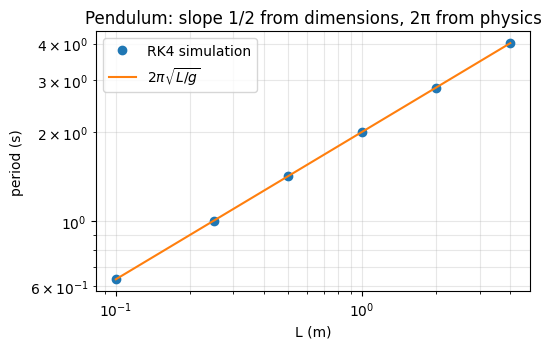

In [5]:
def pendulum_period(L, g, theta0, dt_fraction=2e-4):
    """Period by RK4 integration from rest at theta0: 4 x (time to first reach theta = 0)."""
    w2 = g / L
    dt = dt_fraction * 2 * math.pi / math.sqrt(w2)
    f = lambda th, om: (om, -w2 * math.sin(th))
    th, om, t = theta0, 0.0, 0.0
    while True:
        k1 = f(th, om)
        k2 = f(th + 0.5*dt*k1[0], om + 0.5*dt*k1[1])
        k3 = f(th + 0.5*dt*k2[0], om + 0.5*dt*k2[1])
        k4 = f(th + dt*k3[0], om + dt*k3[1])
        th_new = th + dt/6*(k1[0] + 2*k2[0] + 2*k3[0] + k4[0])
        om_new = om + dt/6*(k1[1] + 2*k2[1] + 2*k3[1] + k4[1])
        if th_new <= 0.0:                       # crossed the bottom: interpolate the crossing time
            return 4 * (t + dt * th / (th - th_new))
        th, om, t = th_new, om_new, t + dt

lengths = np.array([0.1, 0.25, 0.5, 1.0, 2.0, 4.0])
periods = np.array([pendulum_period(L, 9.81, 0.01) for L in lengths])
slope, intercept = np.polyfit(np.log(lengths), np.log(periods), 1)
C = np.mean(periods / np.sqrt(lengths / 9.81))
print(f"log-log slope = {slope:.5f}   (dimensional analysis says 1/2)")
print(f"prefactor  C  = {C:.5f}   (2*pi = {2*math.pi:.5f})")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.loglog(lengths, periods, "o", label="RK4 simulation")
ax.loglog(lengths, 2*math.pi*np.sqrt(lengths/9.81), "-", label=r"$2\pi\sqrt{L/g}$")
ax.set(xlabel="L (m)", ylabel="period (s)", title="Pendulum: slope 1/2 from dimensions, 2π from physics")
ax.legend(); ax.grid(alpha=0.3, which="both"); fig.tight_layout(); plt.show()

# Part 3 — Buckingham Pi: count and find the dimensionless groups

With $n$ variables and a dimension matrix of rank $r$ there are $n-r$
independent dimensionless groups, the null space of $D$. Any physical law
among the variables can be rewritten as a relation among those groups only.

**Pipe flow** $(\rho, v, L, \mu)$: one group, the Reynolds number.
**Drag** $(F, \rho, v, L, \mu)$: two groups, so $F/(\rho v^2L^2)=f(\mathrm{Re})$.

In [6]:
flow = {"rho": DIMS["density"], "v": DIMS["velocity"], "L": DIMS["length"], "mu": DIMS["viscosity"]}
print("pipe flow:", count_pi_groups(flow), "group ->", power_law_str(buckingham_pi(flow)[0]))

drag = dict(F=DIMS["force"], **flow)
groups = buckingham_pi(drag)
print("drag     :", count_pi_groups(drag), "groups")
for g in groups:
    print("   ", power_law_str(g), "   dimension:", dim_str(group_dimension(g, drag)))

# The basis is not unique. Pi_2 / Pi_1 is also dimensionless -- and it is Re^2.
ratio = {k: groups[1].get(k, 0) - groups[0].get(k, 0) for k in drag}
print("Pi_2 / Pi_1 =", power_law_str(ratio), " = Re^2")

pipe flow: 1 group -> rho v L mu^-1
drag     : 2 groups
    F rho^-1 v^-2 L^-2    dimension: 1
    F rho mu^-2    dimension: 1
Pi_2 / Pi_1 = rho^2 v^2 L^2 mu^-2  = Re^2


### Data collapse: the theorem doing real work

For a pendulum released from a **large** angle $\theta_0$, the variables are
$(T, L, g, \theta_0)$. $\theta_0$ is already dimensionless, so there are two
groups and the theorem says
$$T\sqrt{g/L}=f(\theta_0).$$
Pendulums of any length on any planet must fall on **one** curve. Below:
nine simulated pendulums (three lengths under Earth, Moon and Jupiter
gravity), each released from twelve angles, plotted raw and then in the
dimensionless variable.

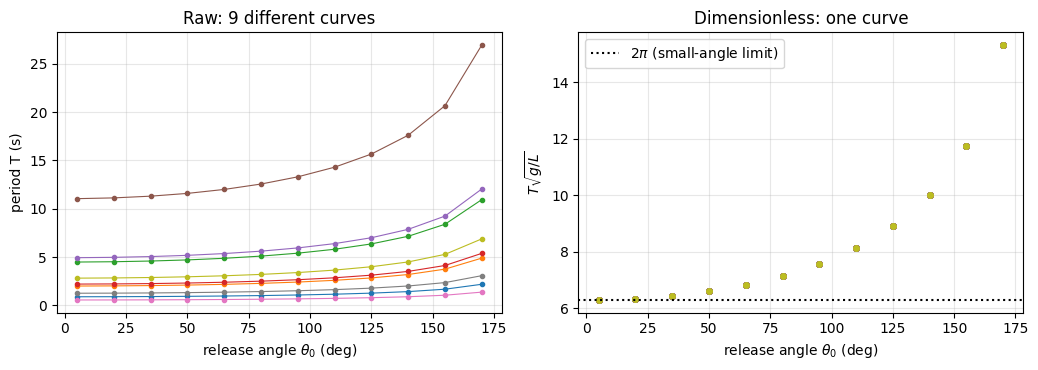

largest relative spread between the 9 pendulums after rescaling: 8.5e-15


In [7]:
planets = {"Earth": 9.81, "Moon": 1.62, "Jupiter": 24.79}
angles = np.radians(np.linspace(5, 170, 12))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
spread = []
for planet, g in planets.items():
    for L in (0.2, 1.0, 5.0):
        T = np.array([pendulum_period(L, g, a, dt_fraction=1e-3) for a in angles])
        axes[0].plot(np.degrees(angles), T, "o-", ms=3, lw=0.8)
        axes[1].plot(np.degrees(angles), T * math.sqrt(g / L), "o", ms=4)
        spread.append(T * math.sqrt(g / L))
spread = np.array(spread)
axes[0].set(xlabel=r"release angle $\theta_0$ (deg)", ylabel="period T (s)", title="Raw: 9 different curves")
axes[1].axhline(2*math.pi, color="k", ls=":", label=r"$2\pi$ (small-angle limit)")
axes[1].set(xlabel=r"release angle $\theta_0$ (deg)", ylabel=r"$T\sqrt{g/L}$", title="Dimensionless: one curve")
axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

print(f"largest relative spread between the 9 pendulums after rescaling: "
      f"{np.max(spread.std(axis=0) / spread.mean(axis=0)):.1e}")

# Part 4 — Modern physics: scales built from constants

The same solver, with physical constants as the "variables".

**The fine-structure constant.** $(k_ee^2, \hbar, c)$ has exactly one
dimensionless group. Its value is not a convention; it is a number nature
chose.

In [8]:
names = ("ke2", "hbar", "c")
g = buckingham_pi({n: CONSTANTS[n][1] for n in names})[0]
alpha = evaluate_group(g, {n: CONSTANTS[n][0] for n in names})
print(f"Pi group of (ke2, hbar, c):  {power_law_str(g)}  =  {alpha:.9f}  =  1/{1/alpha:.4f}")

Pi group of (ke2, hbar, c):  ke2 hbar^-1 c^-1  =  0.007297353  =  1/137.0360


**Atomic and Planck scales.** Each row is the *unique* power law of
the listed constants with the target dimension. The last column compares with
the accepted value of the named quantity.

In [9]:
rows = [
    ("Bohr radius",         "length", ["hbar", "m_e", "ke2"], 5.29177210903e-11, "m"),
    ("Hartree energy",      "energy", ["hbar", "m_e", "ke2"], 4.3597447222071e-18, "J"),
    ("reduced Compton",     "length", ["hbar", "m_e", "c"],   3.8615926796e-13,  "m"),
    ("Planck length",       "length", ["hbar", "G", "c"],     1.616255e-35,      "m"),
    ("Planck time",         "time",   ["hbar", "G", "c"],     5.391247e-44,      "s"),
    ("Planck mass",         "mass",   ["hbar", "G", "c"],     2.176434e-8,       "kg"),
]
print(f"{'quantity':<17}{'power law':<27}{'value':>13}  {'accepted':>13}  ratio")
for label, target, consts, accepted, unit in rows:
    value, exps = scale(DIMS[target], consts)
    print(f"{label:<17}{power_law_str(exps):<27}{value:>13.5e}  {accepted:>13.5e}  {value/accepted:.6f} {unit}")

hartree_eV = joule_to_ev(scale(DIMS['energy'], ['hbar', 'm_e', 'ke2'])[0])
print(f"\nHartree = {hartree_eV:.4f} eV.  Hydrogen ground-state binding energy = 13.6057 eV = Hartree / 2.")
print("The factor 1/2 is a pure number: dimensional analysis cannot produce it.")

quantity         power law                          value       accepted  ratio
Bohr radius      hbar^2 m_e^-1 ke2^-1         5.29177e-11    5.29177e-11  1.000000 m
Hartree energy   hbar^-2 m_e ke2^2            4.35974e-18    4.35974e-18  1.000000 J
reduced Compton  hbar m_e^-1 c^-1             3.86159e-13    3.86159e-13  1.000000 m
Planck length    hbar^1/2 G^1/2 c^-3/2        1.61626e-35    1.61626e-35  1.000000 m
Planck time      hbar^1/2 G^1/2 c^-5/2        5.39125e-44    5.39125e-44  1.000000 s
Planck mass      hbar^1/2 G^-1/2 c^1/2        2.17643e-08    2.17643e-08  1.000000 kg

Hartree = 27.2114 eV.  Hydrogen ground-state binding energy = 13.6057 eV = Hartree / 2.
The factor 1/2 is a pure number: dimensional analysis cannot produce it.


### Where it fails, on purpose

Add $c$ to the atomic list and ask for "the" length scale. Now a dimensionless
group ($\alpha$) exists among the constants, so infinitely many lengths fit:
$\ell\,\alpha^p$ for any $p$. The solver refuses. The three famous electron
lengths are exactly that family, spaced by one power of $\alpha$.

In [10]:
try:
    scale(DIMS["length"], ["hbar", "m_e", "ke2", "c"])
except ValueError as err:
    print("solver:", err)

a0 = scale(DIMS["length"], ["hbar", "m_e", "ke2"])[0]         # Bohr radius
lam = scale(DIMS["length"], ["hbar", "m_e", "c"])[0]          # reduced Compton wavelength
r_e = scale(DIMS["length"], ["ke2", "m_e", "c"])[0]           # classical electron radius
print(f"\nBohr radius               a0    = {a0:.4e} m")
print(f"reduced Compton           lam_C = {lam:.4e} m   lam_C / a0  = {lam/a0:.6e}   alpha   = {alpha:.6e}")
print(f"classical electron radius r_e   = {r_e:.4e} m   r_e / a0    = {r_e/a0:.6e}   alpha^2 = {alpha**2:.6e}")

solver:

 not unique: 1 dimensionless group(s) exist among ['hbar', 'm_e', 'ke2', 'c']; drop a variable or fix the group's value

Bohr radius               a0    = 5.2918e-11 m
reduced Compton           lam_C = 3.8616e-13 m   lam_C / a0  = 7.297353e-03   alpha   = 7.297353e-03
classical electron radius r_e   = 2.8179e-15 m   r_e / a0    = 5.325135e-05   alpha^2 = 5.325135e-05


### Blackbody radiation: right form, wrong number

From $(k_B,\hbar,c)$ the only combination with the dimension of
W m$^{-2}$ K$^{-4}$ is $k_B^4/(\hbar^3c^2)$. The Stefan-Boltzmann constant has
that form times $\pi^2/60$. Likewise Wien's displacement constant is
$hc/k_B$ divided by 4.965 (the root of a transcendental equation). Dimensions
give the form; Planck's integral gives the number.

In [11]:
sb, sb_exps = scale(dim(M=1, T=-3, Th=-4), ["k_B", "hbar", "c"])
print(f"form: {power_law_str(sb_exps)} = {sb:.4e} W m^-2 K^-4")
print(f"accepted sigma = 5.6704e-08  ->  prefactor = {5.670374419e-8/sb:.5f}   (pi^2/60 = {math.pi**2/60:.5f})")

wien, w_exps = scale(dim_mul(DIMS["length"], DIMS["temperature"]), ["h", "c", "k_B"])
print(f"\nform: {power_law_str(w_exps)} = {wien:.5e} m K")
print(f"accepted Wien b = 2.89777e-03 m K  ->  hc/k_B is {wien/2.897771955e-3:.4f} times too large")

form: k_B^4 hbar^-3 c^-2 = 3.4472e-07 W m^-2 K^-4
accepted sigma = 5.6704e-08  ->  prefactor = 0.16449   (pi^2/60 = 0.16449)

form: h c k_B^-1 = 1.43878e-02 m K
accepted Wien b = 2.89777e-03 m K  ->  hc/k_B is 4.9651 times too large


# Part 5 — G. I. Taylor's blast wave

A point release of energy $E$ into air of density $\rho$. If the fireball
radius $R$ depends only on $(E,\rho,t)$, the form is forced:
$$R = C\left(\frac{E\,t^2}{\rho}\right)^{1/5},\qquad\text{so}\qquad E=\frac{\rho R^5}{C^5t^2}.$$
For air, Taylor's full calculation gives $C\approx1.03$, so $C=1$ is a fair
estimate. Taylor used this to estimate the yield of the 1945 Trinity test
from published photographs that carried a time stamp and a scale bar.

The numbers below are a **rough, commonly quoted reading of one frame**
($R\approx140$ m at $t\approx25$ ms), not a careful measurement.

In [12]:
blast = {"E": DIMS["energy"], "rho": DIMS["density"], "t": DIMS["time"]}
exps = solve_power_law(DIMS["length"], blast)
print("R ~", power_law_str(exps))

R, t, rho = 140.0, 0.025, 1.2            # m, s, kg/m^3 (approximate frame reading)
E = rho * R**5 / t**2                     # prefactor taken as 1
kt = E / 4.184e12                         # 1 kiloton TNT = 4.184e12 J
print(f"E ~ {E:.2e} J ~ {kt:.0f} kilotons of TNT   (accepted yield: roughly 20 kt)")
print(f"R is known to ~5 % from a photo -> E is uncertain by ~{5*5} % (fifth power).")

R ~ E^1/5 rho^-1/5 t^2/5
E ~ 1.03e+14 J ~ 25 kilotons of TNT   (accepted yield: roughly 20 kt)
R is known to ~5 % from a photo -> E is uncertain by ~25 % (fifth power).


# Part 6 — Units as measuring sticks: light-time, eV, and this repo

**Light-seconds.** Setting $c$ as the conversion factor turns distances into
times. This is not exotic: it is why an oscilloscope probe cable or a PCB
trace adds delay to a digital signal. One light-nanosecond is 30 cm.

In [13]:
print(f"1 light-nanosecond          = {light_distance(1e-9)*100:6.2f} cm  (about one foot)")
print(f"1 m coax cable (v = 0.66 c) = {light_travel_time(1.0, 0.66)*1e9:6.2f} ns delay")
trace_ns = light_travel_time(0.15, 0.5) * 1e9
print(f"15 cm PCB trace (v ~ 0.5 c) = {trace_ns:6.2f} ns  -> {trace_ns*100:.0f} % of a 1 ns (1 GHz) clock period")
print(f"Earth -> Moon  (3.844e8 m)  = {light_travel_time(3.844e8):6.3f} light-seconds")
print(f"Sun   -> Earth (1.496e11 m) = {light_travel_time(1.496e11):6.1f} light-seconds "
      f"= {light_travel_time(1.496e11)/60:.2f} light-minutes")

1 light-nanosecond          =  29.98 cm  (about one foot)
1 m coax cable (v = 0.66 c) =   5.05 ns delay
15 cm PCB trace (v ~ 0.5 c) =   1.00 ns  -> 100 % of a 1 ns (1 GHz) clock period
Earth -> Moon  (3.844e8 m)  =  1.282 light-seconds
Sun   -> Earth (1.496e11 m) =  499.0 light-seconds = 8.32 light-minutes


**Electron-volts and natural units.** With $\hbar$ and $c$ as conversion
factors, energy, inverse length and mass are the same axis. Two numbers worth
memorising for modern physics: $hc\approx1240$ eV nm and
$\hbar c\approx197$ MeV fm.

In [14]:
hc_eV_nm = energy_to_wavelength(ev_to_joule(1.0)) * 1e9
print(f"h*c    = {hc_eV_nm:.2f} eV nm      hbar*c = {HBAR_C_MEV_FM:.3f} MeV fm")
print(f"electron rest energy  m_e c^2 = {mass_to_rest_energy_ev(CONSTANTS['m_e'][0])/1e6:.5f} MeV")
print(f"proton   rest energy  m_p c^2 = {mass_to_rest_energy_ev(CONSTANTS['m_p'][0])/1e6:.3f} MeV")
for label, nm in (("HeNe laser", 632.8), ("telecom C-band", 1550.0)):
    print(f"{label:<15} {nm:7.1f} nm  ->  photon energy {hc_eV_nm/nm:.3f} eV")

h*c    = 1239.84 eV nm      hbar*c = 197.327 MeV fm
electron rest energy  m_e c^2 = 0.51100 MeV
proton   rest energy  m_p c^2 = 938.272 MeV
HeNe laser        632.8 nm  ->  photon energy 1.959 eV
telecom C-band   1550.0 nm  ->  photon energy 0.800 eV


**Tie to this repo: the dispersion length.** A pulse of duration $T_0$ in
a fiber with group-velocity dispersion $\beta_2$ (units s$^2$/m). The only
length you can build is
$$L_D=\frac{T_0^2}{|\beta_2|},$$
the distance over which dispersion reshapes the pulse. It is the scale that
decides how much fiber the time-stretch forward model
$H(f)=e^{j\pi Df^2}$ in this repo needs. Typical standard single-mode fiber at
1550 nm has $\beta_2\approx-21.7$ ps$^2$/km (a textbook value; check your
fiber's datasheet).

In [15]:
exps = solve_power_law(DIMS["length"], {"T0": DIMS["time"], "beta2": DIMS["gvd"]})
print("L_D ~", power_law_str(exps))

beta2 = 21.7e-24 / 1e3                    # |beta_2| in s^2/m
for T0 in (100e-15, 1e-12, 10e-12, 100e-12):
    print(f"T0 = {T0*1e12:7.1f} ps  ->  L_D = {T0**2/beta2:12.2f} m")
print("\nA 100x longer pulse needs 10 000x more fiber: L_D scales as T0 squared.")

L_D ~ T0^2 beta2^-1
T0 =     0.1 ps  ->  L_D =         0.46 m
T0 =     1.0 ps  ->  L_D =        46.08 m
T0 =    10.0 ps  ->  L_D =      4608.29 m
T0 =   100.0 ps  ->  L_D =    460829.49 m

A 100x longer pulse needs 10 000x more fiber: L_D scales as T0 squared.


# What dimensional analysis did and did not do here

| Example | Got from dimensions | Needed physics for |
|---|---|---|
| Pendulum | $T\propto\sqrt{L/g}$, no mass dependence | the $2\pi$; the large-angle curve $f(\theta_0)$ |
| Drag | $F/(\rho v^2L^2)=f(\mathrm{Re})$ | the function $f$ (experiment or Navier-Stokes) |
| Hydrogen | Bohr radius, Hartree energy | the factor $\tfrac12$ in 13.6 eV |
| Blackbody | $\sigma\propto k_B^4/\hbar^3c^2$ | $\pi^2/60$ |
| Blast wave | $R\propto(Et^2/\rho)^{1/5}$ | $C\approx1.03$; that only $(E,\rho,t)$ matter |

Three limits to keep in mind:

1. **The variable list is a physical assumption.** Leave out a variable that
   matters and the answer is confidently wrong. Dimensions cannot tell you
   the list is incomplete.
2. **No prefactors.** They are usually of order one, but "usually" is not
   "always" ($\pi^2/60\approx0.16$; Wien's $1/4.965$).
3. **No unique answer once a dimensionless group exists.** Then the best
   statement is "group 1 is some function of group 2", and finding that
   function is the actual physics problem.

**Exercises**

1. Add the string tension to the pendulum list. How many Pi groups now, and
   why does it not change the period?
2. Find the frequency scale of an $LC$ circuit and of a mass on a spring with
   `solve_power_law`. Compare the two exponent patterns.
3. A capillary wave depends on surface tension (N/m), density and wavelength.
   Derive how its frequency scales with wavelength.